# 19 — First 15:30 intraday update

The experiment was executed locally through `build_intraday_1530_update.py`. These cells inspect saved results. The daily-only control isolates the contribution of current-session information.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'blackrock_data').exists())
out = root / 'outputs/experiments/19_intraday_1530'

,candidate,development_rmse_log,development_wape,development_bias,confirmation_rmse_log,confirmation_wape,confirmation_bias
0,checkpoint_ratio_rule,0.691529,0.492621,-0.156346,0.614224,0.466934,-0.090475
1,fixed_daily,0.469491,0.354676,-0.144684,0.429014,0.328298,-0.090003
2,lgbm_daily_control,0.478712,0.359470,-0.133879,0.430338,0.332277,-0.071158
3,lgbm_intraday_update,0.462146,0.347655,-0.119335,0.415594,0.321218,-0.058610
4,ridge_update,0.459954,0.345919,-0.118001,0.409157,0.317815,-0.069106


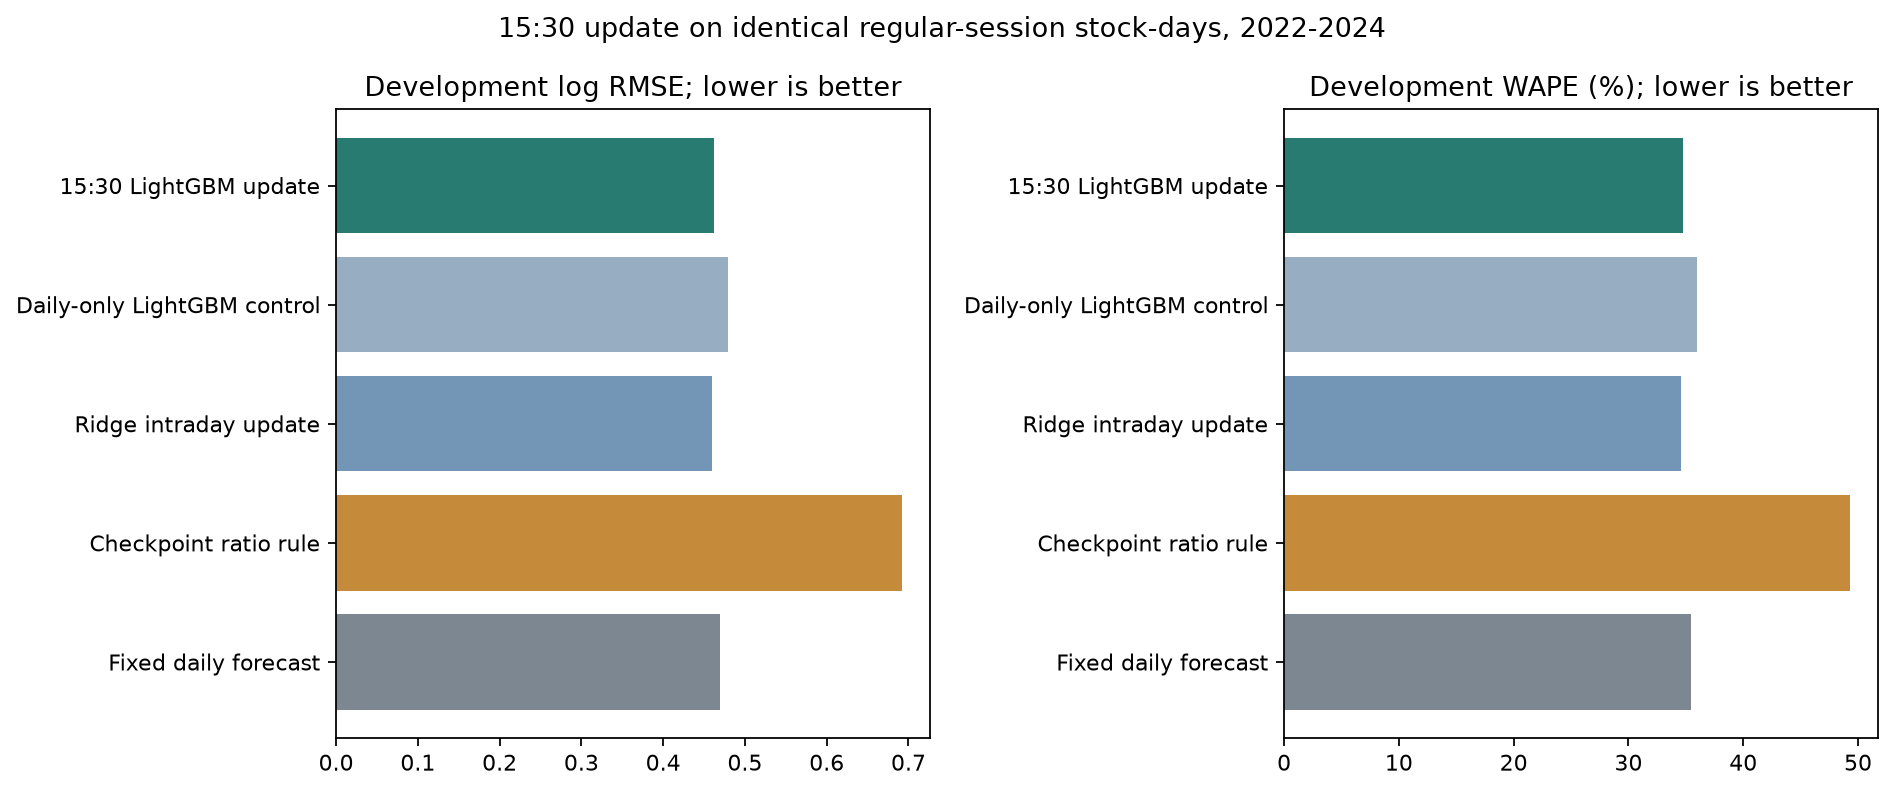

In [2]:
display(pd.read_csv(out / 'intraday_comparison.csv'))
display(Image(filename=str(out / 'intraday_comparison.png')))

In [3]:
display(pd.read_csv(out / 'coverage_by_year.csv'))
display(pd.read_csv(out / 'intraday_information_gate.csv'))
display(pd.read_csv(out / 'paired_bootstrap.csv'))

,year,eligible_targets,early_close_rows,regular_session_rows,valid_checkpoint_rows,daily_fallback_rows,invalid_daily_forecasts
0,2021,321564,1294,320270,320214,56,0
1,2022,328634,1279,327355,327156,199,0
2,2023,318679,2520,316159,316091,68,0
3,2024,316212,3730,312482,312479,3,0
4,2025,307853,3681,304172,304171,1,0


,reference,rmse_change,worst_annual_rmse_change,wape_change,paired_log_mae_ci_upper,passes
0,fixed_daily,-0.007345,-0.003584,-0.007021,-0.005431,True
1,lgbm_daily_control,-0.016567,-0.014935,-0.011815,-0.012309,True


,candidate,reference,period,metric,dates,mean_difference,ci_2_5,ci_97_5
0,checkpoint_ratio_rule,fixed_daily,development,log_mae_delta,747,0.139863,0.127823,0.152492
1,checkpoint_ratio_rule,fixed_daily,development,daily_wape_delta,747,0.113712,0.108233,0.118950
2,checkpoint_ratio_rule,fixed_daily,confirmation,log_mae_delta,247,0.123292,0.104423,0.148458
3,checkpoint_ratio_rule,fixed_daily,confirmation,daily_wape_delta,247,0.118375,0.108578,0.128427
4,checkpoint_ratio_rule,lgbm_daily_control,development,log_mae_delta,747,0.133437,0.121289,0.146445
5,checkpoint_ratio_rule,lgbm_daily_control,development,daily_wape_delta,747,0.108715,0.102502,0.114623
6,checkpoint_ratio_rule,lgbm_daily_control,confirmation,log_mae_delta,247,0.119845,0.100548,0.145122
7,checkpoint_ratio_rule,lgbm_daily_control,confirmation,daily_wape_delta,247,0.114044,0.103891,0.124630
8,ridge_update,fixed_daily,development,log_mae_delta,747,-0.010010,-0.011566,-0.008490
9,ridge_update,fixed_daily,development,daily_wape_delta,747,-0.009352,-0.010794,-0.007926


In [4]:
display(pd.read_csv(out / 'segment_diagnostics.csv'))
checks = pd.read_csv(out / 'validation_checks.csv')
assert checks.passed.all()
display(checks)

,candidate,dimension,segment,observations,rmse_log,wape,aggregate_bias
0,fixed_daily,size,large,329475,0.396853,0.329388,-0.120311
1,fixed_daily,size,small,289404,0.580339,0.447202,-0.237463
2,fixed_daily,size,mid,337117,0.431558,0.388017,-0.177834
3,fixed_daily,history,seasoned,952795,0.467838,0.353337,-0.143927
4,fixed_daily,history,cold_0_4,750,1.513502,0.856865,-0.659964
...,...,...,...,...,...,...,...
65,lgbm_intraday_update,event,regular,864853,0.442151,0.304699,-0.080698
66,lgbm_intraday_update,event,month_end,44999,0.659020,0.471678,-0.272192
67,lgbm_intraday_update,event,quarterly_expiry,15431,0.734848,0.524782,-0.261561
68,lgbm_intraday_update,availability,available,955726,0.463676,0.346551,-0.118701


,check,passed
0,forbidden_current_daily_outcomes_not_inputs,True
1,2022_unique_keys,True
2,2022_proper_year,True
3,2022_all_regular_session_keys_and_labels,True
4,2022_daily_reference_unchanged,True
...,...,...
119,2025_lgbm_intraday_update_feature_allowlist,True
120,2025_lgbm_intraday_update_serialized_model_rec...,True
121,independent_prior_window_checkpoint_avg_volume20,True
122,independent_prior_window_checkpoint_avg_trades20,True
